# Regularized Cost and Gradient

In [10]:
import numpy as np
%matplotlib widget
import matplotlib.pyplot as plt
from plt_overfit import overfit_example, output
from function import sigmoid
np.set_printoptions(precision=8)

## Cost function with Regularization 

### Cost function for regularized linear regression  
- The equation for the cost function regularized linear regression is:  
  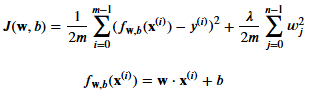

In [11]:
def compute_cost_linear_reg(X,y,w,b, lambda_ = 1):
    m = X.shape[0]
    n = len(w)

    cost = 0.
    for i in range(m):
        f_wb_i = np.dot(X[i],w) + b
        cost = cost + (f_wb_i - y[i])**2
    cost = (cost)/(2*m)

    reg_cost = 0
    for j in range(n):
        reg_cost += (w[j]**2)
    reg_cost = ((lambda_)/(2*m))*reg_cost

    total_cost = cost + reg_cost
    return total_cost

In [12]:
np.random.seed(1)
X_tmp = np.random.rand(5,6)
y_tmp = np.array([0,1,0,1,0])
w_tmp = np.random.rand(X_tmp.shape[1]) - 0.5
b_tmp = 0.5
lambda_tmp = 0.7
cost_tmp = compute_cost_linear_reg(X_tmp,y_tmp,w_tmp,b_tmp,lambda_tmp)

print("Regularization cost:", cost_tmp)

Regularization cost: 0.07917239320214275


### Cost function for regularized logistic regression
- cost function is:  
  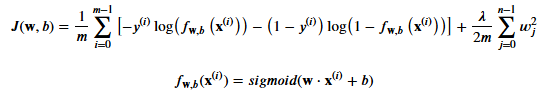

In [13]:
def compute_cost_logistic_reg(X,y,w,b,lambda_):

    m,n = X.shape

    cost = 0.
    for i in range(m):
        z_i = np.dot(X[i],w) + b
        f_wb_i = sigmoid(z_i)
        cost += (-y[i]) * np.log(f_wb_i) - (1-y[i]) * np.log(1 - f_wb_i)
    cost = cost/m

    reg_cost = 0.
    for j in range(n):
        reg_cost += w[j]**2
    reg_cost = (lambda_/(2*m)) * reg_cost

    total_cost = cost + reg_cost
    return total_cost

In [14]:
np.random.seed(1)
X_tmp = np.random.rand(5,6)
y_tmp = np.array([0,1,0,1,0])
w_tmp = np.random.rand(X_tmp.shape[1]) - 0.5
b_tmp = 0.5
lambda_tmp = 0.7

cost_tmp = compute_cost_logistic_reg(X_tmp,y_tmp,w_tmp,b_tmp,lambda_tmp)
print("Regularized cost:", cost_tmp)

Regularized cost: 0.6850849138741673


## Gradient Descent with Regularization
- The basic algorith does not change with regularization it is,  
  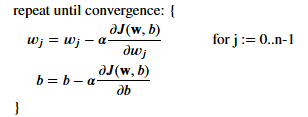

### Computing the Gradient with regularization (both linear/logistic)
- The gradient calculation is same for both just $f_{w,b}$ differ.  
  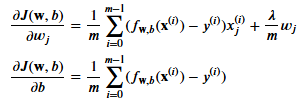

#### Gradient function for regularized linear regression

In [15]:
def compute_gradient_linear_reg(X,y,w,b,lambda_):
    m,n = X.shape
    dj_dw = np.zeros(n)
    dj_db = 0.

    for i in range(m):
        err = (np.dot(X[i],w) + b) - y[i]
        for j in range(n):
            dj_dw[j] += err * X[i,j]
        dj_db += err

    dj_dw /= m
    dj_db /= m

    for j in range(n):
        dj_dw[j] += (lambda_/m) * w[j]

    return dj_db,dj_dw

In [16]:
np.random.seed(1)
X_tmp = np.random.rand(5,3)
y_tmp = np.array([0,1,0,1,0])
w_tmp = np.random.rand(X_tmp.shape[1])
b_tmp = 0.5
lambda_tmp = 0.7

dj_db_tmp, dj_dw_tmp = compute_gradient_linear_reg(X_tmp,y_tmp,w_tmp,b_tmp,lambda_tmp)

print(f"dj_db: {dj_db_tmp}")
print(f"Regularized dj_dw: {dj_dw_tmp}")

dj_db: 0.6648774569425726
Regularized dj_dw: [0.29653215 0.49116796 0.21645878]


#### Gradient function for regularized logistic regression 

In [17]:
def compute_gradient_logistic_reg(X,y,w,b,lambda_):
    m,n = X.shape
    dj_dw = np.zeros(n)
    dj_db = 0.

    for i in range(m):
        err_i = sigmoid(np.dot(X[i],w) + b) - y[i]
        for j in range(n):
            dj_dw[j] += err_i * X[i,j]
        dj_db += err_i

    dj_dw /= m
    dj_db /= m

    for j in range(n):
        dj_dw[j] += (lambda_/m) * w[j]

    return dj_db,dj_dw

In [18]:
np.random.seed(1)
X_tmp = np.random.rand(5,3)
y_tmp = np.array([0,1,0,1,0])
w_tmp = np.random.rand(X_tmp.shape[1])
b_tmp = 0.5
lambda_tmp = 0.7

dj_db_tmp, dj_dw_tmp = compute_gradient_logistic_reg(X_tmp,y_tmp,w_tmp,b_tmp,lambda_tmp)

print(f"dj_db: {dj_db_tmp}")
print(f"regularized dj_dw: {dj_dw_tmp}")

dj_db: 0.341798994972791
regularized dj_dw: [0.17380013 0.32007508 0.10776313]
